# Finding matching points between photos with SIFT

**Goal:** detect distinctive keypoints in photos of the same building taken from different angles, distances and cameras, and match them with the **SIFT** algorithm (Lowe, 1999/2004).

**Data:** my own photos of two buildings, the side wall of a house and the facade of a block of flats, taken with two different phone cameras. All metadata was removed from the images.

**Pipeline:** SIFT keypoints and 128-dimensional descriptors → k-nearest-neighbour matching (brute force and FLANN) → Lowe's ratio test to keep only distinctive matches.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

IMG = Path("../images")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"savefig.dpi": 150, "savefig.bbox": "tight", "savefig.facecolor": "white",
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})

sift = cv.SIFT_create()
flann = cv.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))  # KD-tree index
bf = cv.BFMatcher()
print("OpenCV", cv.__version__)

def load(name):
    return cv.imread(str(IMG / name), cv.IMREAD_COLOR)

def features(img):
    return sift.detectAndCompute(cv.cvtColor(img, cv.COLOR_BGR2GRAY), None)

def knn(a, b, matcher=flann):
    cv.setRNGSeed(42)  # FLANN's randomised KD-trees: fix the seed for reproducible counts
    return matcher.knnMatch(a, b, k=2)

def ratio_test(knn, ratio):
    return [m for m, n in knn if m.distance < ratio * n.distance]

OpenCV 5.0.0


## 1. Keypoints

house_1: 12,468 keypoints, house_2: 14,736 keypoints, descriptor size 128


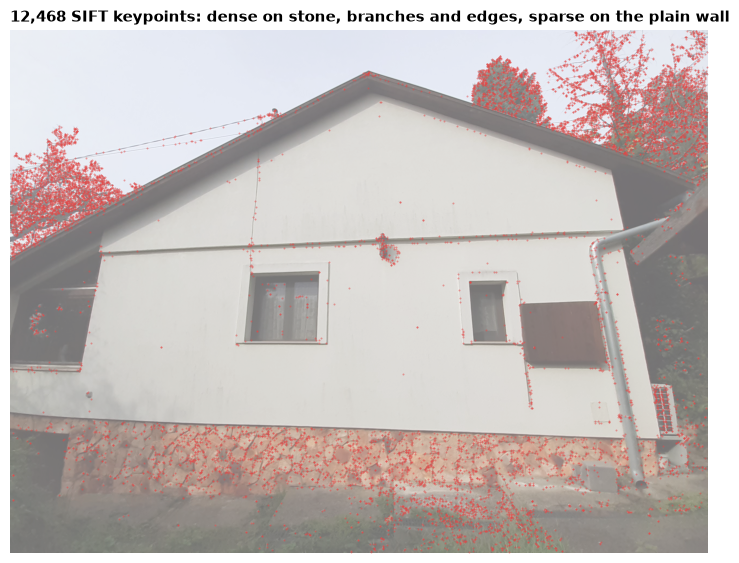

In [2]:
house1, house2 = load("house_1.jpg"), load("house_2.jpg")
kp1, des1 = features(house1)
kp2, des2 = features(house2)
print(f"house_1: {len(kp1):,} keypoints, house_2: {len(kp2):,} keypoints, descriptor size {des1.shape[1]}")

pts = np.array([k.pt for k in kp1])
fig, ax = plt.subplots(figsize=(9, 6.8))
ax.imshow(cv.cvtColor(house1, cv.COLOR_BGR2RGB), alpha=0.55)
ax.scatter(pts[:, 0], pts[:, 1], s=2, c="#e34948", alpha=0.5, linewidths=0)
ax.set_axis_off()
ax.set_title(f"{len(kp1):,} SIFT keypoints: dense on stone, branches and edges, sparse on the plain wall")
fig.savefig(FIG / "01_keypoints.png")

## 2. Matching and the ratio test

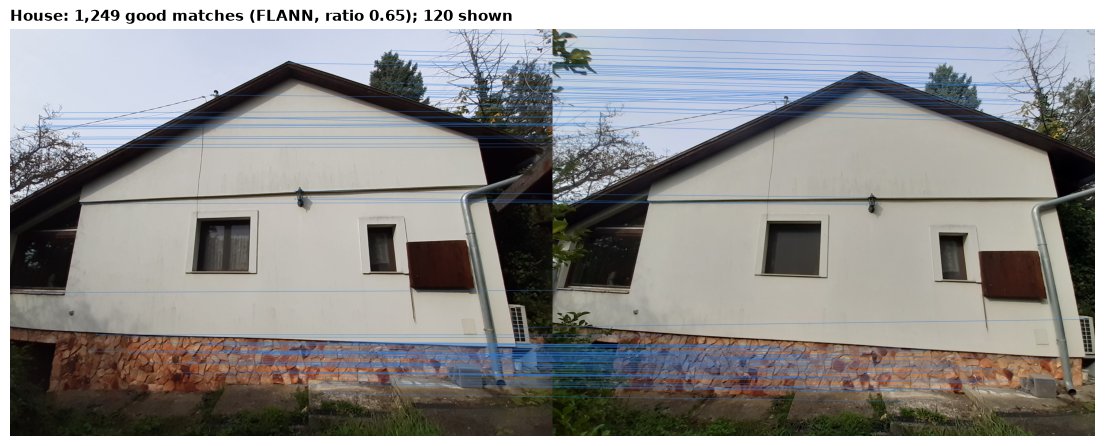

In [3]:
def draw(img1, kps1, img2, kps2, good, name, title, max_lines=120):
    rng = np.random.default_rng(0)
    shown = list(rng.choice(good, size=min(max_lines, len(good)), replace=False)) if good else []
    out = cv.drawMatches(img1, kps1, img2, kps2, shown, None, matchColor=(214, 120, 42),
                         singlePointColor=None, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    fig, ax = plt.subplots(figsize=(14, 5.5))
    ax.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB))
    ax.set_axis_off()
    ax.set_title(title)
    fig.savefig(FIG / f"{name}.png")

good_house = ratio_test(knn(des1, des2), 0.65)
draw(house1, kp1, house2, kp2, good_house, "02_house_matches",
     f"House: {len(good_house):,} good matches (FLANN, ratio 0.65); 120 shown")

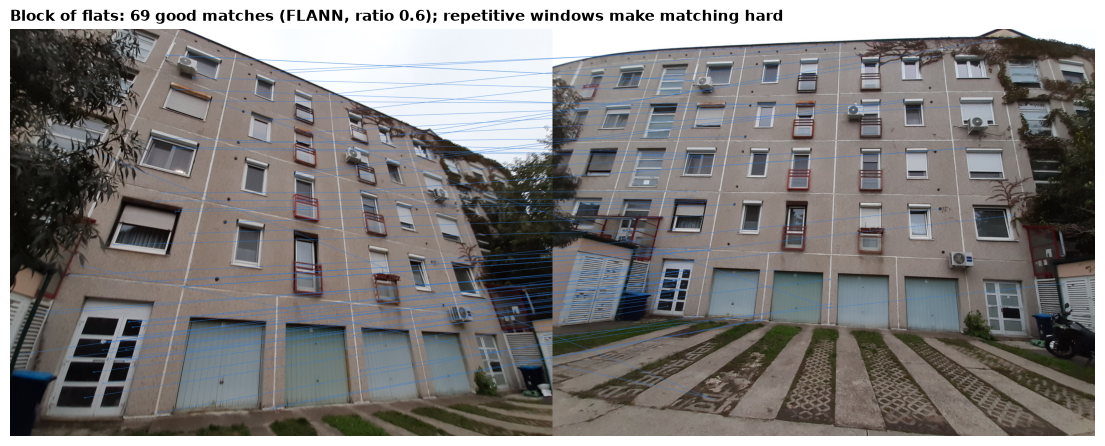

In [4]:
panels = {n: load(f"panel_{n}.jpg") for n in (1, 2, 3, 4)}
pf = {n: features(img) for n, img in panels.items()}
good_p12 = ratio_test(knn(pf[1][1], pf[2][1]), 0.6)
draw(panels[1], pf[1][0], panels[2], pf[2][0], good_p12, "03_panel_matches",
     f"Block of flats: {len(good_p12)} good matches (FLANN, ratio 0.6); repetitive windows make matching hard", max_lines=80)

## 3. How strict should the ratio test be?

In [5]:
pairs = {
    "House 1 – 2": (des1, des2),
    "Flats 1 – 2": (pf[1][1], pf[2][1]),
    "Flats 1 – 3": (pf[1][1], pf[3][1]),
    "Flats 1 – 4": (pf[1][1], pf[4][1]),
}
rows = []
for name, (a, b) in pairs.items():
    knn_f = knn(a, b)
    knn_b = knn(a, b, bf)
    rows.append({"Pair": name, "Keypoints (img 1 / img 2)": f"{len(a):,} / {len(b):,}",
                 "FLANN 0.60": len(ratio_test(knn_f, 0.60)), "FLANN 0.65": len(ratio_test(knn_f, 0.65)),
                 "FLANN 0.70": len(ratio_test(knn_f, 0.70)), "Brute force 0.68": len(ratio_test(knn_b, 0.68))})
table = pd.DataFrame(rows).set_index("Pair")
table.to_csv(FIG / "match_counts.csv")
table

,Keypoints (img 1 / img 2),FLANN 0.60,FLANN 0.65,FLANN 0.70,Brute force 0.68
Pair,,,,,
House 1 – 2,"12,468 / 14,736",1084,1249,1452,1328
Flats 1 – 2,"8,409 / 12,617",69,107,167,122
Flats 1 – 3,"8,409 / 7,012",26,48,106,62
Flats 1 – 4,"8,409 / 9,771",431,536,674,592


## 4. Conclusions

1. **Texture-rich scenes match well.** The house photos, with brickwork and tree branches, yield more than a thousand reliable matches. The algorithm also finds matches on surrounding objects such as the branches.
2. **Repetitive structures are hard.** The identical windows of a block of flats produce far fewer good matches, from a few dozen to a few hundred depending on the viewpoint. Some of them are visibly false, for example between the wall and the concrete strip in front of the garages.
3. **The ratio threshold trades quantity for reliability.** A lower ratio keeps fewer but more distinctive matches. FLANN gives practically the same result as brute-force matching, much faster on large descriptor sets.

*Reference:* Lowe, D. G. (2004). Distinctive image features from scale-invariant keypoints. *International Journal of Computer Vision*, 60(2), 91–110.